In [1]:
from pathlib import Path
from decimal import Decimal

import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 20)

CSV_PATH = Path(
    r"D:\Users\BuiTrongNguyen\CodexProject\dwdss-hotel-booking"
    r"\artifacts\mart\sample\daily_hotel_operations_202610271639.csv"
)

if not CSV_PATH.is_file():
    raise FileNotFoundError(CSV_PATH)

print("File:", CSV_PATH.name)

File: daily_hotel_operations_202610271639.csv


In [2]:
def read_decimal(value):
    return None if value == "" else Decimal(value)


boolean_columns = [
    "is_weekend",
    "is_holiday",
    "has_national_holiday",
    "has_lisboa_holiday",
]

df_raw = pd.read_csv(
    CSV_PATH,
    encoding="utf-8-sig",
    parse_dates=["full_date"],
    dtype={
        "data_version": "string",
        "target_guests": "Int64",
        **{column: "boolean" for column in boolean_columns},
    },
    true_values=["true"],
    false_values=["false"],
    keep_default_na=False,
    na_values=[""],
    converters={
        "sum_adr": read_decimal,
        "avg_adr": read_decimal,
    },
)

df = df_raw.sort_values("full_date").reset_index(drop=True).copy()

print(f"Đã đọc {df.shape[0]:,} dòng × {df.shape[1]} cột")
display(df.head(10))

Đã đọc 793 dòng × 45 cột


,date_key,full_date,year,quarter,month,iso_year,iso_week,day_of_week,is_weekend,data_version,is_holiday,has_national_holiday,has_lisboa_holiday,holiday_names,temperature_mean,precipitation,holiday_data_status,temperature_status,precipitation_status,booking_data_status,guest_data_status,stay_data_status,rejected_booking_count,guest_ineligible_booking_count,stay_ineligible_booking_count,total_bookings,non_canceled_bookings,total_cancellations,guest_valid_booking_count,stay_valid_booking_count,lead_time_valid_count,adr_valid_count,observed_total_adults,observed_total_children,observed_total_babies,observed_total_guests,observed_total_stay_nights,sum_lead_time,sum_adr,cancellation_rate,avg_party_size,avg_stay_nights,avg_lead_time,avg_adr,target_guests
0,20150701,2015-07-01,2015,3,7,2015,27,3,False,75deb861-6eb3-4475-8b15-f23bcef91b9b,False,False,False,{},19.1,0.1,COMPLETE,COMPLETE,COMPLETE,COMPLETE,COMPLETE,COMPLETE,0,0,0,79,65,14,65,65,65,65,116,0,0,116,136,16302,6180.0,0.177215,1.784615,2.092308,250.800000,95.0769230769230769,116
1,20150702,2015-07-02,2015,3,7,2015,27,4,False,75deb861-6eb3-4475-8b15-f23bcef91b9b,False,False,False,{},19.3,0.0,COMPLETE,COMPLETE,COMPLETE,COMPLETE,COMPLETE,COMPLETE,0,0,0,49,1,48,1,1,1,1,1,0,0,1,3,3,58.67,0.979592,1.000000,3.000000,3.000000,58.6700000000000000,1
2,20150703,2015-07-03,2015,3,7,2015,27,5,False,75deb861-6eb3-4475-8b15-f23bcef91b9b,False,False,False,{},19.4,0.0,COMPLETE,COMPLETE,COMPLETE,COMPLETE,COMPLETE,COMPLETE,0,0,0,16,10,6,10,10,10,10,18,0,0,18,25,408,745.27,0.375000,1.800000,2.500000,40.800000,74.5270000000000000,18
3,20150704,2015-07-04,2015,3,7,2015,27,6,True,75deb861-6eb3-4475-8b15-f23bcef91b9b,False,False,False,{},21.1,0.0,COMPLETE,COMPLETE,COMPLETE,COMPLETE,COMPLETE,COMPLETE,0,0,0,38,9,29,9,9,9,9,16,0,0,16,36,2098,574,0.763158,1.777778,4.000000,233.111111,63.7777777777777778,16
4,20150705,2015-07-05,2015,3,7,2015,27,7,True,75deb861-6eb3-4475-8b15-f23bcef91b9b,False,False,False,{},19.9,0.0,COMPLETE,COMPLETE,COMPLETE,COMPLETE,COMPLETE,COMPLETE,0,0,0,8,0,8,0,0,0,0,0,0,0,0,0,0,0,1.000000,NaN,NaN,NaN,None,0
5,20150706,2015-07-06,2015,3,7,2015,28,1,False,75deb861-6eb3-4475-8b15-f23bcef91b9b,False,False,False,{},20.3,0.0,COMPLETE,COMPLETE,COMPLETE,COMPLETE,COMPLETE,COMPLETE,0,0,0,30,1,29,1,1,1,1,2,0,0,2,1,185,66.13,0.966667,2.000000,1.000000,185.000000,66.1300000000000000,2
6,20150707,2015-07-07,2015,3,7,2015,28,2,False,75deb861-6eb3-4475-8b15-f23bcef91b9b,False,False,False,{},20.7,0.0,COMPLETE,COMPLETE,COMPLETE,COMPLETE,COMPLETE,COMPLETE,0,0,0,19,2,17,2,2,2,2,4,1,0,5,12,123,138.45,0.894737,2.500000,6.000000,61.500000,69.2250000000000000,5
7,20150708,2015-07-08,2015,3,7,2015,28,3,False,75deb861-6eb3-4475-8b15-f23bcef91b9b,False,False,False,{},19.8,0.0,COMPLETE,COMPLETE,COMPLETE,COMPLETE,COMPLETE,COMPLETE,0,0,0,40,24,16,24,24,24,24,47,0,0,47,54,5673,1426.0,0.400000,1.958333,2.250000,236.375000,59.4166666666666667,47
8,20150709,2015-07-09,2015,3,7,2015,28,4,False,75deb861-6eb3-4475-8b15-f23bcef91b9b,False,False,False,{},19.7,0.0,COMPLETE,COMPLETE,COMPLETE,COMPLETE,COMPLETE,COMPLETE,0,0,0,46,1,45,1,1,1,1,2,0,0,2,5,92,58.9,0.978261,2.000000,5.000000,92.000000,58.9000000000000000,2
9,20150710,2015-07-10,2015,3,7,2015,28,5,False,75deb861-6eb3-4475-8b15-f23bcef91b9b,False,False,False,{},19.6,0.0,COMPLETE,COMPLETE,COMPLETE,COMPLETE,COMPLETE,COMPLETE,0,0,0,9,2,7,2,2,2,2,4,2,0,6,9,203,186.69,0.777778,3.000000,4.500000,101.500000,93.3450000000000000,6


In [3]:
df.info()

overview = pd.DataFrame({
    "Thông tin": [
        "Số dòng",
        "Số cột",
        "Ngày đầu",
        "Ngày cuối",
        "Số ngày phân biệt",
        "Số dòng trùng date_key",
        "Số phiên bản dữ liệu",
    ],
    "Giá trị": [
        len(df),
        df.shape[1],
        df["full_date"].min().date(),
        df["full_date"].max().date(),
        df["full_date"].nunique(),
        df["date_key"].duplicated().sum(),
        df["data_version"].nunique(dropna=False),
    ],
})

display(overview)

<class 'pandas.DataFrame'>
RangeIndex: 793 entries, 0 to 792
Data columns (total 45 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   date_key                        793 non-null    int64         
 1   full_date                       793 non-null    datetime64[us]
 2   year                            793 non-null    int64         
 3   quarter                         793 non-null    int64         
 4   month                           793 non-null    int64         
 5   iso_year                        793 non-null    int64         
 6   iso_week                        793 non-null    int64         
 7   day_of_week                     793 non-null    int64         
 8   is_weekend                      793 non-null    boolean       
 9   data_version                    793 non-null    string        
 10  is_holiday                      793 non-null    boolean       
 11  has_national_holi

,Thông tin,Giá trị
0,Số dòng,793
1,Số cột,45
2,Ngày đầu,2015-07-01
3,Ngày cuối,2017-08-31
4,Số ngày phân biệt,793
5,Số dòng trùng date_key,0
6,Số phiên bản dữ liệu,1


In [4]:
missing = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": df.isna().mean().mul(100).round(2),
}).sort_values("missing_count", ascending=False)

display(missing)

status_columns = [
    "booking_data_status",
    "guest_data_status",
    "stay_data_status",
    "holiday_data_status",
    "temperature_status",
    "precipitation_status",
]

status_long = df[status_columns].melt(
    var_name="status_column",
    value_name="status",
)

status_summary = pd.crosstab(
    status_long["status_column"],
    status_long["status"],
)

display(status_summary)

,dtype,missing_count,missing_pct
target_guests,Int64,114,14.38
avg_party_size,float64,5,0.63
avg_lead_time,float64,5,0.63
avg_stay_nights,float64,5,0.63
avg_adr,object,5,0.63
...,...,...,...
observed_total_children,int64,0,0.00
observed_total_adults,int64,0,0.00
cancellation_rate,float64,0,0.00
sum_lead_time,int64,0,0.00


status,COMPLETE,PARTIAL
status_column,,
booking_data_status,793,0
guest_data_status,679,114
holiday_data_status,793,0
precipitation_status,793,0
stay_data_status,793,0
temperature_status,793,0


In [5]:
view_columns = [
    "full_date",
    "total_bookings",
    "non_canceled_bookings",
    "total_cancellations",
    "cancellation_rate",
    "observed_total_guests",
    "guest_valid_booking_count",
    "guest_ineligible_booking_count",
    "guest_data_status",
    "target_guests",
    "observed_total_stay_nights",
    "is_weekend",
    "is_holiday",
    "temperature_mean",
    "precipitation",
]

display(df[view_columns].head(10))

print("Ví dụ những ngày guest PARTIAL:")
display(
    df.loc[df["guest_data_status"].eq("PARTIAL"), view_columns].head(10)
)

,full_date,total_bookings,non_canceled_bookings,total_cancellations,cancellation_rate,observed_total_guests,guest_valid_booking_count,guest_ineligible_booking_count,guest_data_status,target_guests,observed_total_stay_nights,is_weekend,is_holiday,temperature_mean,precipitation
0,2015-07-01,79,65,14,0.177215,116,65,0,COMPLETE,116,136,False,False,19.1,0.1
1,2015-07-02,49,1,48,0.979592,1,1,0,COMPLETE,1,3,False,False,19.3,0.0
2,2015-07-03,16,10,6,0.375000,18,10,0,COMPLETE,18,25,False,False,19.4,0.0
3,2015-07-04,38,9,29,0.763158,16,9,0,COMPLETE,16,36,True,False,21.1,0.0
4,2015-07-05,8,0,8,1.000000,0,0,0,COMPLETE,0,0,True,False,19.9,0.0
5,2015-07-06,30,1,29,0.966667,2,1,0,COMPLETE,2,1,False,False,20.3,0.0
6,2015-07-07,19,2,17,0.894737,5,2,0,COMPLETE,5,12,False,False,20.7,0.0
7,2015-07-08,40,24,16,0.400000,47,24,0,COMPLETE,47,54,False,False,19.8,0.0
8,2015-07-09,46,1,45,0.978261,2,1,0,COMPLETE,2,5,False,False,19.7,0.0
9,2015-07-10,9,2,7,0.777778,6,2,0,COMPLETE,6,9,False,False,19.6,0.0


Ví dụ những ngày guest PARTIAL:


,full_date,total_bookings,non_canceled_bookings,total_cancellations,cancellation_rate,observed_total_guests,guest_valid_booking_count,guest_ineligible_booking_count,guest_data_status,target_guests,observed_total_stay_nights,is_weekend,is_holiday,temperature_mean,precipitation
22,2015-07-23,91,39,52,0.571429,73,38,1,PARTIAL,<NA>,45,False,False,21.0,0.0
24,2015-07-25,149,62,87,0.583893,112,61,1,PARTIAL,<NA>,155,True,False,19.4,0.0
39,2015-08-09,30,28,2,0.066667,61,27,1,PARTIAL,<NA>,74,True,False,23.4,0.0
40,2015-08-10,138,72,66,0.478261,141,71,1,PARTIAL,<NA>,225,False,False,22.3,0.0
41,2015-08-11,67,61,6,0.089552,116,59,2,PARTIAL,<NA>,161,False,False,19.7,0.0
56,2015-08-26,93,51,42,0.451613,97,50,1,PARTIAL,<NA>,101,False,False,20.5,0.0
57,2015-08-27,59,14,45,0.762712,34,13,1,PARTIAL,<NA>,38,False,False,21.0,0.0
68,2015-09-07,84,54,30,0.357143,96,53,1,PARTIAL,<NA>,182,False,False,21.2,0.0
72,2015-09-11,179,102,77,0.430168,162,100,2,PARTIAL,<NA>,213,False,False,18.4,0.0
85,2015-09-24,166,65,101,0.608434,108,64,1,PARTIAL,<NA>,161,False,False,18.9,0.0


## So sánh booking theo holiday

In [20]:
df_eda = df.copy().sort_values("full_date").reset_index(drop=True)

if df_eda["full_date"].duplicated().any():
    raise ValueError("Dữ liệu phải có đúng một dòng/ngày.")

if (
    df_eda["is_holiday"].isna().any()
    or not df_eda["holiday_data_status"].eq("COMPLETE").all()
):
    raise ValueError("Cần kiểm tra ngày có thông tin lịch lễ chưa đầy đủ.")

holiday_dates = df_eda.loc[
    df_eda["is_holiday"].eq(True),
    "full_date",
]

holiday_window_dates = pd.DatetimeIndex([
    holiday_date + pd.Timedelta(days=offset)
    for holiday_date in holiday_dates
    for offset in (-3, -2, -1, 0, 1, 2)
]).unique()

df_eda["is_holiday_window_pre2_post1"] = (
    df_eda["full_date"].isin(holiday_window_dates)
)

df_eda["holiday_group"] = (
    df_eda["is_holiday_window_pre2_post1"]
    .map({
        True: "Trong cửa sổ lễ",
        False: "Ngoài cửa sổ lễ",
    })
)

display(
    df_eda[
        [
            "full_date",
            "is_holiday",
            "is_holiday_window_pre2_post1",
            "holiday_group",
            "total_bookings",
        ]
    ].head(20)
)

,full_date,is_holiday,is_holiday_window_pre2_post1,holiday_group,total_bookings
0,2015-07-01,False,False,Ngoài cửa sổ lễ,79
1,2015-07-02,False,False,Ngoài cửa sổ lễ,49
2,2015-07-03,False,False,Ngoài cửa sổ lễ,16
3,2015-07-04,False,False,Ngoài cửa sổ lễ,38
4,2015-07-05,False,False,Ngoài cửa sổ lễ,8
5,2015-07-06,False,False,Ngoài cửa sổ lễ,30
6,2015-07-07,False,False,Ngoài cửa sổ lễ,19
7,2015-07-08,False,False,Ngoài cửa sổ lễ,40
8,2015-07-09,False,False,Ngoài cửa sổ lễ,46
9,2015-07-10,False,False,Ngoài cửa sổ lễ,9


In [21]:
if (
    not df_eda["booking_data_status"].eq("COMPLETE").all()
    or df_eda["total_bookings"].isna().any()
):
    raise ValueError("Cần kiểm tra dữ liệu booking chưa đầy đủ trước khi so sánh.")

comparison = (
    df_eda.groupby("holiday_group")
    .agg(
        number_of_days=("full_date", "nunique"),
        total_bookings=("total_bookings", "sum"),
        bookings_per_day=("total_bookings", "mean"),
        median_bookings_per_day=("total_bookings", "median"),
    )
    .reindex(["Trong cửa sổ lễ", "Ngoài cửa sổ lễ"])
)

display(comparison.round(2))

holiday_mean = comparison.loc["Trong cửa sổ lễ", "bookings_per_day"]
normal_mean = comparison.loc["Ngoài cửa sổ lễ", "bookings_per_day"]

difference = holiday_mean - normal_mean
difference_pct = (holiday_mean / normal_mean - 1) * 100

print(f"Chênh lệch: {difference:+.2f} booking/ngày")
print(f"Chênh lệch tương đối: {difference_pct:+.2f}%")

,number_of_days,total_bookings,bookings_per_day,median_bookings_per_day
holiday_group,,,,
Trong cửa sổ lễ,138,15671,113.56,109.0
Ngoài cửa sổ lễ,655,63659,97.19,94.0


Chênh lệch: +16.37 booking/ngày
Chênh lệch tương đối: +16.84%


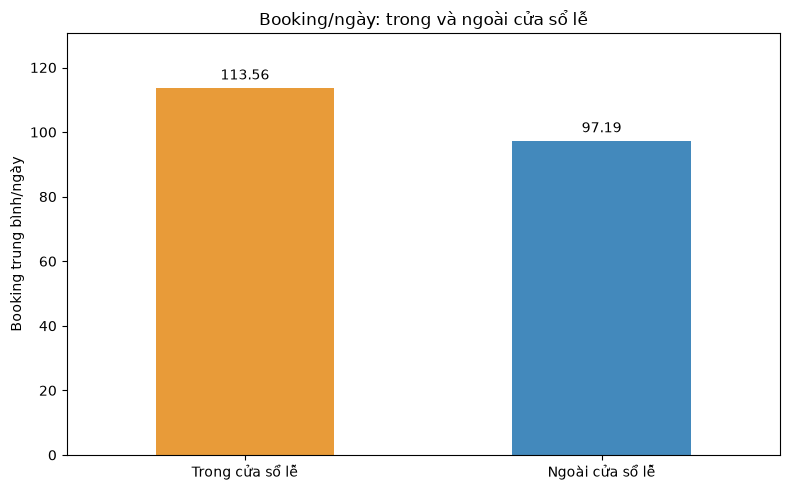

In [22]:
import matplotlib.pyplot as plt

ax = comparison["bookings_per_day"].plot.bar(
    figsize=(8, 5),
    color=["#e89b39", "#4389bc"],
    rot=0,
)

ax.set_title("Booking/ngày: trong và ngoài cửa sổ lễ")
ax.set_xlabel("")
ax.set_ylabel("Booking trung bình/ngày")
ax.bar_label(ax.containers[0], fmt="%.2f", padding=4)
ax.set_ylim(0, comparison["bookings_per_day"].max() * 1.15)

plt.tight_layout()
plt.show()

## Phân loại ngày mưa

In [23]:
RAIN_MEDIUM_START = 2.5
RAIN_HEAVY_START = 10.0

rain_labels = ["Không mưa", "Mưa nhỏ", "Mưa vừa", "Mưa lớn"]

if (
    not df_eda["precipitation_status"].eq("COMPLETE").all()
    or df_eda["precipitation"].isna().any()
    or df_eda["precipitation"].lt(0).any()
):
    raise ValueError("Cần kiểm tra dữ liệu lượng mưa trước khi phân nhóm.")


def classify_rain(mm):
    if mm == 0:
        return "Không mưa"
    if mm < RAIN_MEDIUM_START:
        return "Mưa nhỏ"
    if mm < RAIN_HEAVY_START:
        return "Mưa vừa"
    return "Mưa lớn"


df_eda["rain_group"] = pd.Categorical(
    df_eda["precipitation"].apply(classify_rain),
    categories=rain_labels,
    ordered=True,
)

display(
    df_eda[
        [
            "full_date",
            "precipitation",
            "rain_group",
            "total_bookings",
            "total_cancellations",
        ]
    ].head(15)
)

,full_date,precipitation,rain_group,total_bookings,total_cancellations
0,2015-07-01,0.1,Mưa nhỏ,79,14
1,2015-07-02,0.0,Không mưa,49,48
2,2015-07-03,0.0,Không mưa,16,6
3,2015-07-04,0.0,Không mưa,38,29
4,2015-07-05,0.0,Không mưa,8,8
5,2015-07-06,0.0,Không mưa,30,29
6,2015-07-07,0.0,Không mưa,19,17
7,2015-07-08,0.0,Không mưa,40,16
8,2015-07-09,0.0,Không mưa,46,45
9,2015-07-10,0.0,Không mưa,9,7


## So sánh Cancellation trên Rain_group

In [24]:
if (
    not df_eda["booking_data_status"].eq("COMPLETE").all()
    or df_eda[["total_bookings", "total_cancellations"]].isna().any().any()
):
    raise ValueError("Cần kiểm tra dữ liệu booking trước khi so sánh.")

rain_comparison = (
    df_eda.groupby("rain_group", observed=False)
    .agg(
        number_of_days=("full_date", "nunique"),
        total_bookings=("total_bookings", "sum"),
        total_cancellations=("total_cancellations", "sum"),
    )
)

rain_comparison["cancellations_per_day"] = (
    rain_comparison["total_cancellations"]
    / rain_comparison["number_of_days"].where(
        rain_comparison["number_of_days"] > 0
    )
)

rain_comparison["cancellation_rate_pct"] = (
    rain_comparison["total_cancellations"]
    / rain_comparison["total_bookings"].where(
        rain_comparison["total_bookings"] > 0
    )
    * 100
)

display(rain_comparison.round(2))

,number_of_days,total_bookings,total_cancellations,cancellations_per_day,cancellation_rate_pct
rain_group,,,,,
Không mưa,566,56665,23584,41.67,41.62
Mưa nhỏ,119,12053,5182,43.55,42.99
Mưa vừa,79,8081,3429,43.41,42.43
Mưa lớn,29,2531,907,31.28,35.84


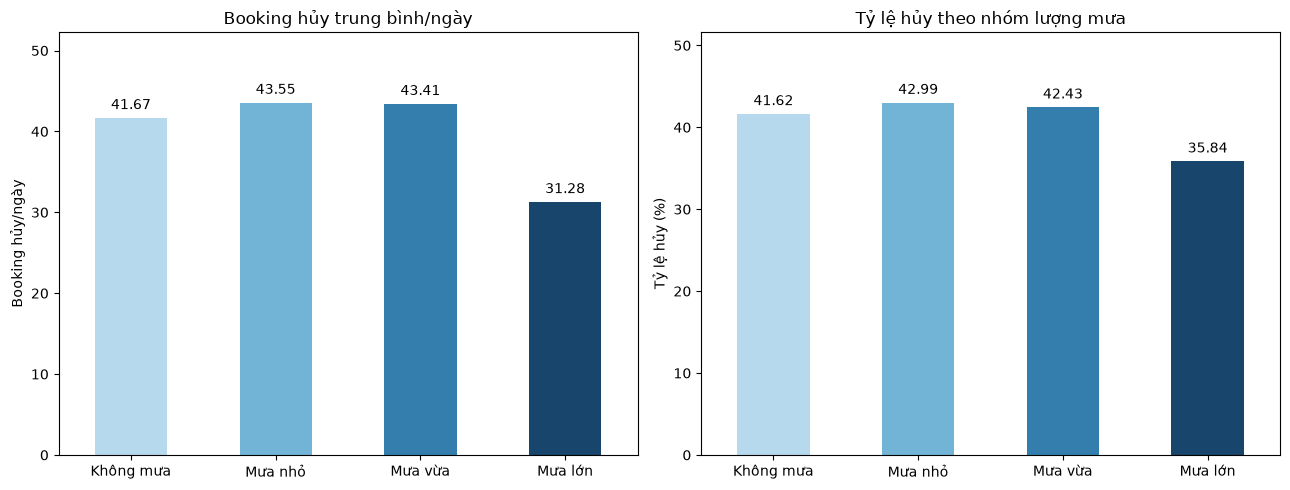

In [25]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = ["#b7d9ed", "#72b4d5", "#347eae", "#17456c"]

metrics = [
    ("cancellations_per_day", "Booking hủy trung bình/ngày", "Booking hủy/ngày"),
    ("cancellation_rate_pct", "Tỷ lệ hủy theo nhóm lượng mưa", "Tỷ lệ hủy (%)"),
]

for ax, (column, title, ylabel) in zip(axes, metrics):
    rain_comparison[column].plot.bar(
        ax=ax, color=colors, rot=0
    )
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.bar_label(ax.containers[0], fmt="%.2f", padding=4)
    ax.set_ylim(0, rain_comparison[column].max() * 1.2)

plt.tight_layout()
plt.show()

In [26]:
booking_by_rain = (
    df_eda.groupby("rain_group", observed=False)
    .agg(
        number_of_days=("full_date", "nunique"),
        total_bookings=("total_bookings", "sum"),
        non_canceled_bookings=("non_canceled_bookings", "sum"),
    )
)

valid_days = booking_by_rain["number_of_days"].where(
    booking_by_rain["number_of_days"] > 0
)

booking_by_rain["total_bookings_per_day"] = (
    booking_by_rain["total_bookings"] / valid_days
)

booking_by_rain["non_canceled_bookings_per_day"] = (
    booking_by_rain["non_canceled_bookings"] / valid_days
)

display(booking_by_rain.round(2))

,number_of_days,total_bookings,non_canceled_bookings,total_bookings_per_day,non_canceled_bookings_per_day
rain_group,,,,,
Không mưa,566,56665,33081,100.11,58.45
Mưa nhỏ,119,12053,6871,101.29,57.74
Mưa vừa,79,8081,4652,102.29,58.89
Mưa lớn,29,2531,1624,87.28,56.00


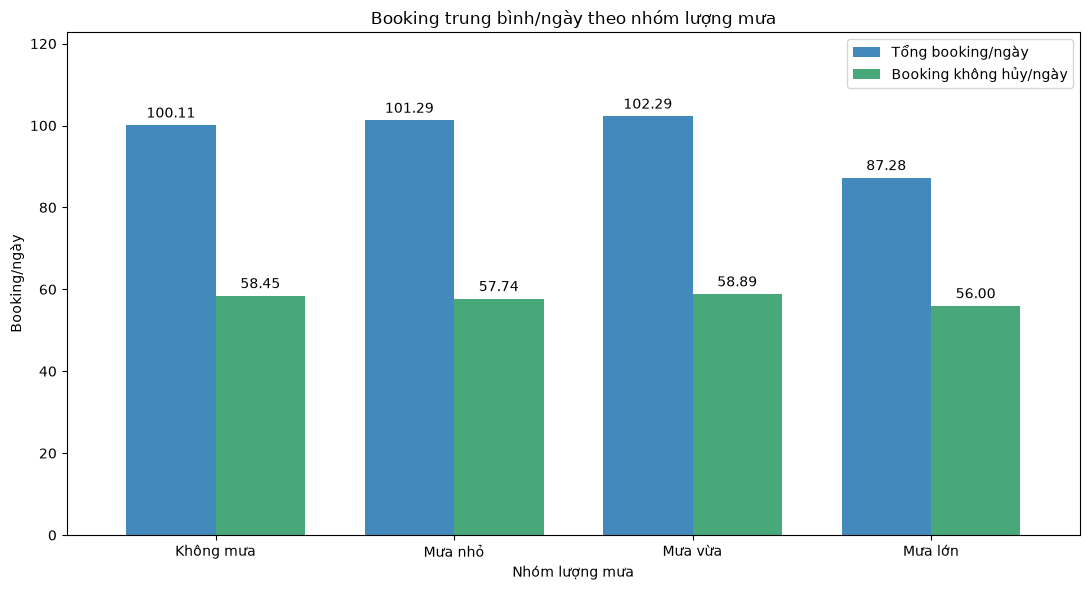

In [27]:
import matplotlib.pyplot as plt

plot_data = booking_by_rain[
    ["total_bookings_per_day", "non_canceled_bookings_per_day"]
].rename(columns={
    "total_bookings_per_day": "Tổng booking/ngày",
    "non_canceled_bookings_per_day": "Booking không hủy/ngày",
})

ax = plot_data.plot.bar(
    figsize=(11, 6),
    color=["#4389bc", "#48a879"],
    rot=0,
    width=0.75,
)

ax.set_title("Booking trung bình/ngày theo nhóm lượng mưa")
ax.set_xlabel("Nhóm lượng mưa")
ax.set_ylabel("Booking/ngày")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

ax.set_ylim(0, plot_data.max().max() * 1.2)
ax.legend(title="")

plt.tight_layout()
plt.show()

## Cái weather lượng mưa này lỏ quá=)

## So sánh booking theo weekday/weekend


In [28]:
df_eda["is_weekend_calendar"] = (
    df_eda["full_date"].dt.dayofweek >= 5
)

# Xem những dòng khác với cờ trong CSV
mismatch = (
    df_eda["is_weekend"].isna()
    | df_eda["is_weekend"].ne(df_eda["is_weekend_calendar"])
)

display(
    df_eda.loc[
        mismatch,
        ["full_date", "is_weekend", "is_weekend_calendar"],
    ]
)

df_eda["day_type"] = df_eda["is_weekend_calendar"].map({
    False: "Ngày thường",
    True: "Cuối tuần",
})

booking_by_day_type = (
    df_eda.groupby("day_type")
    .agg(
        number_of_days=("full_date", "nunique"),
        total_bookings=("total_bookings", "sum"),
        non_canceled_bookings=("non_canceled_bookings", "sum"),
    )
    .reindex(["Ngày thường", "Cuối tuần"])
)

valid_days = booking_by_day_type["number_of_days"].where(
    booking_by_day_type["number_of_days"] > 0
)

booking_by_day_type["total_bookings_per_day"] = (
    booking_by_day_type["total_bookings"] / valid_days
)

booking_by_day_type["non_canceled_bookings_per_day"] = (
    booking_by_day_type["non_canceled_bookings"] / valid_days
)

display(booking_by_day_type.round(2))

C:\Users\Bui Trong Nguyen\AppData\Local\Temp\ipykernel_28008\2715314036.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df_eda["full_date"].dt.dayofweek >= 5


,full_date,is_weekend,is_weekend_calendar
718,2017-06-18,False,True


,number_of_days,total_bookings,non_canceled_bookings,total_bookings_per_day,non_canceled_bookings_per_day
day_type,,,,,
Ngày thường,567,59143,33997,104.31,59.96
Cuối tuần,226,20187,12231,89.32,54.12


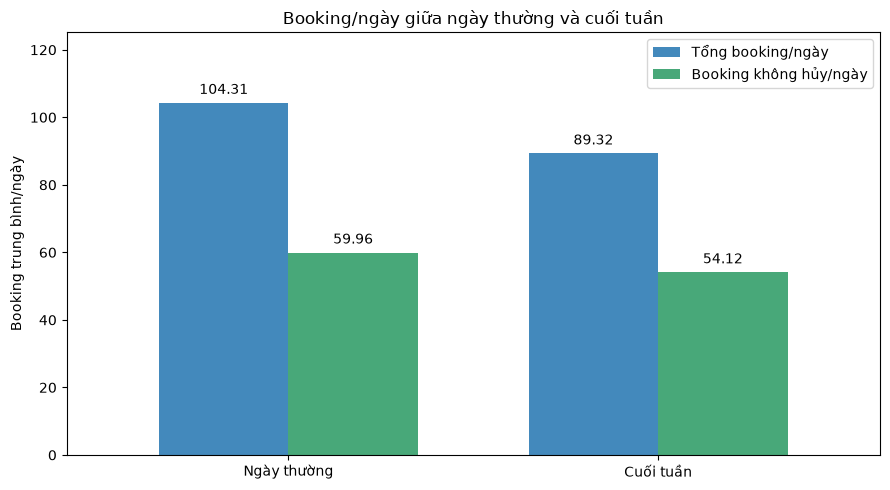

In [29]:
import matplotlib.pyplot as plt

plot_data = booking_by_day_type[
    ["total_bookings_per_day", "non_canceled_bookings_per_day"]
].rename(columns={
    "total_bookings_per_day": "Tổng booking/ngày",
    "non_canceled_bookings_per_day": "Booking không hủy/ngày",
})

ax = plot_data.plot.bar(
    figsize=(9, 5),
    color=["#4389bc", "#48a879"],
    rot=0,
    width=0.7,
)

ax.set_title("Booking/ngày giữa ngày thường và cuối tuần")
ax.set_xlabel("")
ax.set_ylabel("Booking trung bình/ngày")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=4)

ax.set_ylim(0, plot_data.max().max() * 1.2)
ax.legend(title="")

plt.tight_layout()
plt.show()

## Tập data này bị lỏ à 
nhưng không sao, còn nhiều thứ làm lắm

## Chuẩn bị dữ liệu và các nhóm thời gian

In [32]:
import pandas as pd
import matplotlib.pyplot as plt

DAY_NAMES = [
    "Thứ Hai", "Thứ Ba", "Thứ Tư", "Thứ Năm",
    "Thứ Sáu", "Thứ Bảy", "Chủ Nhật",
]

eda = df.copy()

eda["full_date"] = pd.to_datetime(
    eda["full_date"], errors="raise"
).dt.normalize()

if eda["full_date"].isna().any():
    raise ValueError("Có ngày bị thiếu.")

if eda["full_date"].duplicated().any():
    raise ValueError("Dữ liệu phải có đúng một dòng/ngày.")

eda = eda.sort_values("full_date").reset_index(drop=True)

expected_dates = pd.date_range(
    eda["full_date"].min(),
    eda["full_date"].max(),
)

missing_dates = expected_dates.difference(eda["full_date"])

if len(missing_dates):
    raise ValueError(f"Thiếu {len(missing_dates)} ngày trong khoảng phân tích.")

numeric_columns = [
    "total_bookings",
    "non_canceled_bookings",
    "total_cancellations",
    "observed_total_stay_nights",
    "stay_valid_booking_count",
]

for column in numeric_columns:
    eda[column] = pd.to_numeric(
        eda[column], errors="raise"
    ).astype("Int64")

if eda[numeric_columns].isna().any().any():
    raise ValueError("Có measure bị thiếu; cần kiểm tra trước khi tổng hợp.")

for column in ["booking_data_status", "stay_data_status"]:
    if not eda[column].isin(["COMPLETE"]).all():
        raise ValueError(f"{column} có ngày chưa COMPLETE.")

if not (
    eda["total_bookings"]
    == eda["non_canceled_bookings"] + eda["total_cancellations"]
).all():
    raise ValueError("Booking tổng không khớp không hủy + hủy.")

# Dẫn xuất từ ngày lịch, giữ nguyên các cột gốc trong CSV
eda["weekday_number"] = eda["full_date"].dt.dayofweek

eda["weekday_name"] = pd.Categorical(
    eda["weekday_number"].map(dict(enumerate(DAY_NAMES))),
    categories=DAY_NAMES,
    ordered=True,
)

eda["is_weekend_calendar"] = eda["weekday_number"].ge(5)

eda["day_type"] = pd.Categorical(
    eda["is_weekend_calendar"].map({
        False: "Ngày thường",
        True: "Cuối tuần",
    }),
    categories=["Ngày thường", "Cuối tuần"],
    ordered=True,
)

eda["month_start"] = (
    eda["full_date"].dt.to_period("M").dt.to_timestamp()
)

print(f"Số ngày: {len(eda):,}")
print(
    "Khoảng dữ liệu:",
    eda["full_date"].min().date(),
    "→",
    eda["full_date"].max().date(),
)

Số ngày: 793
Khoảng dữ liệu: 2015-07-01 → 2017-08-31


C:\Users\Bui Trong Nguyen\AppData\Local\Temp\ipykernel_28008\3713803872.py:60: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  eda["weekday_number"] = eda["full_date"].dt.dayofweek


### Hàm tổng hợp

In [33]:
def summarize_operations(data, by):
    result = (
        data.groupby(by, observed=True)
        .agg(
            number_of_days=("full_date", "nunique"),
            total_bookings=("total_bookings", "sum"),
            non_canceled_bookings=("non_canceled_bookings", "sum"),
            total_cancellations=("total_cancellations", "sum"),
            observed_total_stay_nights=(
                "observed_total_stay_nights", "sum"
            ),
            stay_valid_booking_count=(
                "stay_valid_booking_count", "sum"
            ),
        )
    )

    days = result["number_of_days"].where(
        result["number_of_days"] > 0
    )
    bookings = result["total_bookings"].where(
        result["total_bookings"] > 0
    )
    valid_stays = result["stay_valid_booking_count"].where(
        result["stay_valid_booking_count"] > 0
    )

    result["total_bookings_per_day"] = (
        result["total_bookings"] / days
    )
    result["non_canceled_bookings_per_day"] = (
        result["non_canceled_bookings"] / days
    )
    result["cancellation_rate_pct"] = (
        result["total_cancellations"] / bookings * 100
    )
    result["avg_stay_nights"] = (
        result["observed_total_stay_nights"] / valid_stays
    )
    result["stay_nights_per_day"] = (
        result["observed_total_stay_nights"] / days
    )

    return result

### Bảng so sánh 7 thứ

In [34]:
by_weekday = summarize_operations(
    eda, "weekday_name"
).reindex(DAY_NAMES)

booking_columns = [
    "number_of_days",
    "total_bookings",
    "non_canceled_bookings",
    "total_bookings_per_day",
    "non_canceled_bookings_per_day",
    "cancellation_rate_pct",
]

display(by_weekday[booking_columns].round(2))

,number_of_days,total_bookings,non_canceled_bookings,total_bookings_per_day,non_canceled_bookings_per_day,cancellation_rate_pct
weekday_name,,,,,,
Thứ Hai,113,11823,7255,104.63,64.2,38.64
Thứ Ba,113,9127,5670,80.77,50.18,37.88
Thứ Tư,114,11229,6572,98.5,57.65,41.47
Thứ Năm,114,13009,6699,114.11,58.76,48.5
Thứ Sáu,113,13955,7801,123.5,69.04,44.1
Thứ Bảy,113,10993,6195,97.28,54.82,43.65
Chủ Nhật,113,9194,6036,81.36,53.42,34.35


### Biểu đồ booking/ngày của 7 thứ

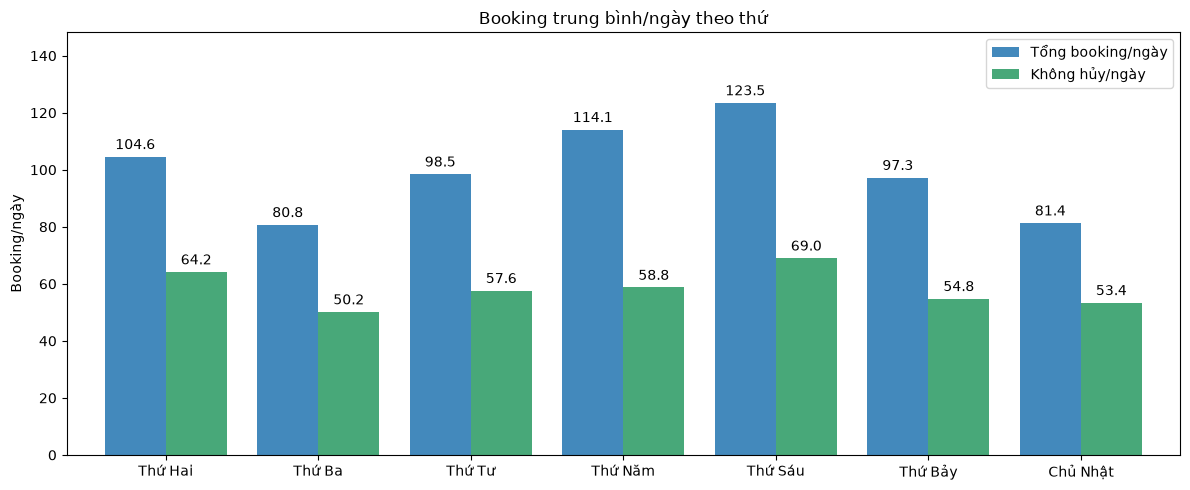

In [35]:
weekday_plot = by_weekday[
    ["total_bookings_per_day", "non_canceled_bookings_per_day"]
].rename(columns={
    "total_bookings_per_day": "Tổng booking/ngày",
    "non_canceled_bookings_per_day": "Không hủy/ngày",
})

ax = weekday_plot.plot.bar(
    figsize=(12, 5),
    color=["#4389bc", "#48a879"],
    rot=0,
    width=0.8,
)

ax.set_title("Booking trung bình/ngày theo thứ")
ax.set_xlabel("")
ax.set_ylabel("Booking/ngày")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)

ax.set_ylim(0, weekday_plot.max().max() * 1.2)
ax.legend(title="")

plt.tight_layout()
plt.show()

### Bảng theo tháng–năm

Cột full_month giúp nhận biết tháng có đủ ngày trong khoảng phân tích.

In [36]:
by_month = summarize_operations(
    eda, "month_start"
).sort_index()

by_month["calendar_days"] = by_month.index.days_in_month

by_month["full_month"] = (
    by_month["number_of_days"] == by_month["calendar_days"]
)

display(
    by_month[
        [
            "number_of_days",
            "calendar_days",
            "full_month",
            "total_bookings_per_day",
            "non_canceled_bookings_per_day",
            "cancellation_rate_pct",
        ]
    ].round(2)
)

,number_of_days,calendar_days,full_month,total_bookings_per_day,non_canceled_bookings_per_day,cancellation_rate_pct
month_start,,,,,,
2015-07-01,31,31,True,45.1,14.81,67.17
2015-08-01,31,31,True,80.0,40.26,49.68
2015-09-01,30,30,True,117.63,66.2,43.72
2015-10-01,31,31,True,109.23,66.61,39.01
2015-11-01,30,30,True,41.17,31.13,24.37
...,...,...,...,...,...,...
2017-04-01,30,30,True,130.63,66.43,49.15
2017-05-01,31,31,True,146.97,75.45,48.66
2017-06-01,30,30,True,132.37,72.1,45.53


### Xu hướng booking/ngày theo tháng–năm

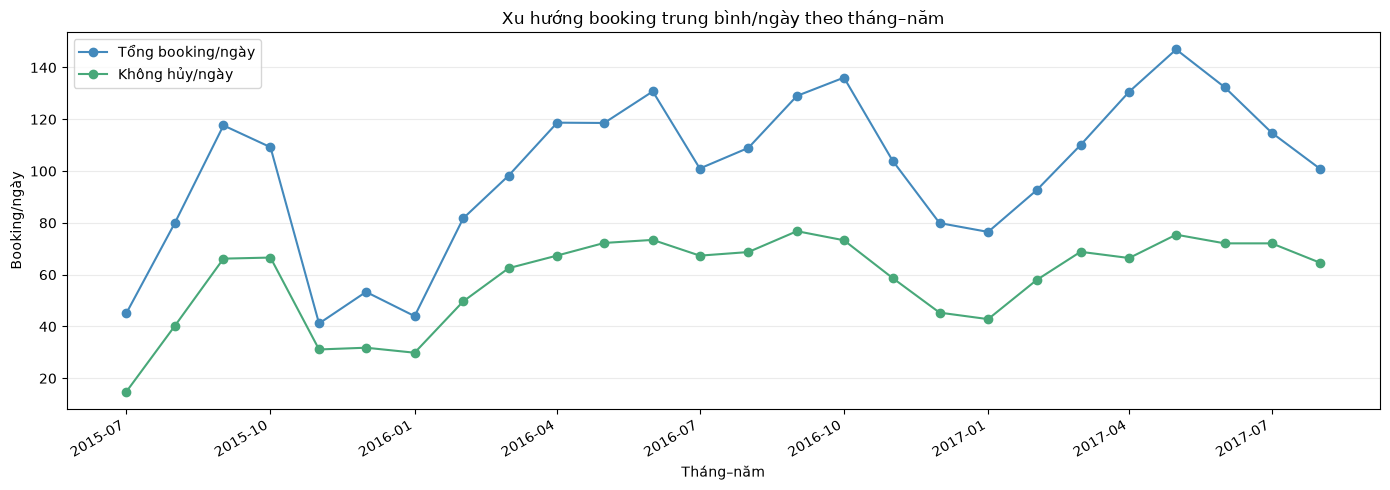

In [37]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    by_month.index,
    by_month["total_bookings_per_day"],
    marker="o",
    label="Tổng booking/ngày",
    color="#4389bc",
)

ax.plot(
    by_month.index,
    by_month["non_canceled_bookings_per_day"],
    marker="o",
    label="Không hủy/ngày",
    color="#48a879",
)

ax.set_title("Xu hướng booking trung bình/ngày theo tháng–năm")
ax.set_xlabel("Tháng–năm")
ax.set_ylabel("Booking/ngày")
ax.grid(axis="y", alpha=0.25)
ax.legend()

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### So ngày thường/cuối tuần riêng trong từng tháng–năm

day_type,Ngày thường,Cuối tuần,difference,difference_pct
month_start,,,,
2015-07-01,13.57,18.38,4.81,35.46
2015-08-01,44.24,31.9,-12.34,-27.89
2015-09-01,70.14,55.38,-14.76,-21.05
2015-10-01,69.77,58.89,-10.88,-15.6
2015-11-01,36.67,18.22,-18.44,-50.3
...,...,...,...,...
2017-04-01,69.8,59.7,-10.1,-14.47
2017-05-01,76.52,72.38,-4.15,-5.42
2017-06-01,73.27,68.88,-4.4,-6.0


Số tháng so sánh được: 26
Cuối tuần cao hơn: 8
Cuối tuần thấp hơn: 18


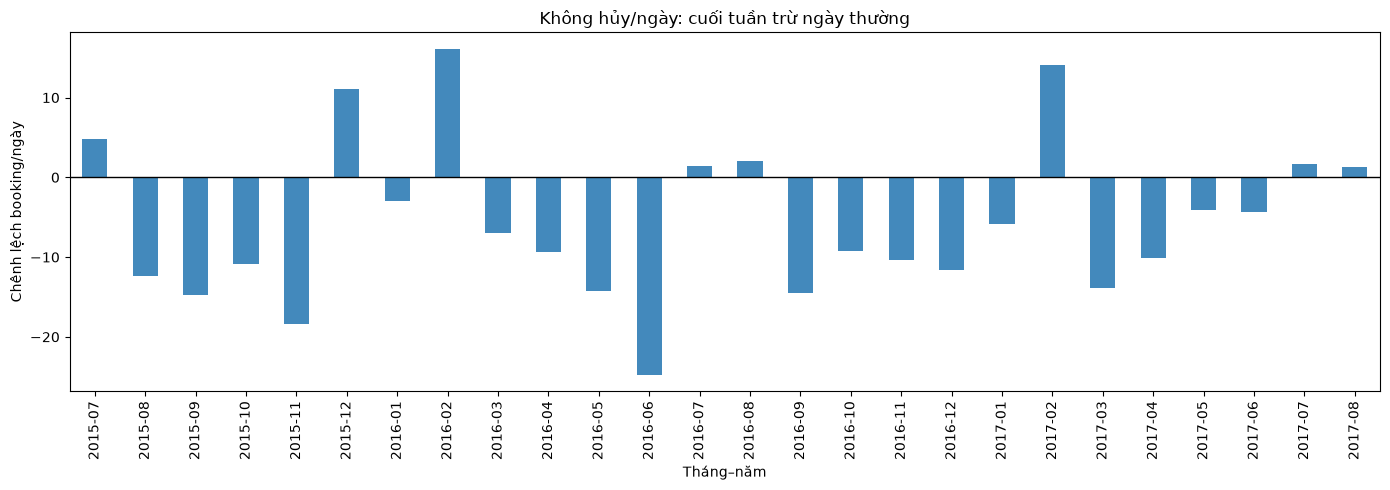

In [38]:
by_month_day_type = summarize_operations(
    eda, ["month_start", "day_type"]
)

monthly_weekend_comparison = (
    by_month_day_type["non_canceled_bookings_per_day"]
    .unstack("day_type")
    .reindex(columns=["Ngày thường", "Cuối tuần"])
)

monthly_weekend_comparison["difference"] = (
    monthly_weekend_comparison["Cuối tuần"]
    - monthly_weekend_comparison["Ngày thường"]
)

weekday_reference = monthly_weekend_comparison[
    "Ngày thường"
].where(monthly_weekend_comparison["Ngày thường"] > 0)

monthly_weekend_comparison["difference_pct"] = (
    monthly_weekend_comparison["difference"]
    / weekday_reference
    * 100
)

display(monthly_weekend_comparison.round(2))

difference = monthly_weekend_comparison["difference"]

print("Số tháng so sánh được:", difference.notna().sum())
print("Cuối tuần cao hơn:", difference.gt(0).sum())
print("Cuối tuần thấp hơn:", difference.lt(0).sum())

ax = difference.rename(
    index=lambda value: value.strftime("%Y-%m")
).plot.bar(
    figsize=(14, 5),
    color="#4389bc",
)

ax.axhline(0, color="black", linewidth=1)
ax.set_title("Không hủy/ngày: cuối tuần trừ ngày thường")
ax.set_xlabel("Tháng–năm")
ax.set_ylabel("Chênh lệch booking/ngày")

plt.tight_layout()
plt.show()

### Heatmap tháng–năm × thứ

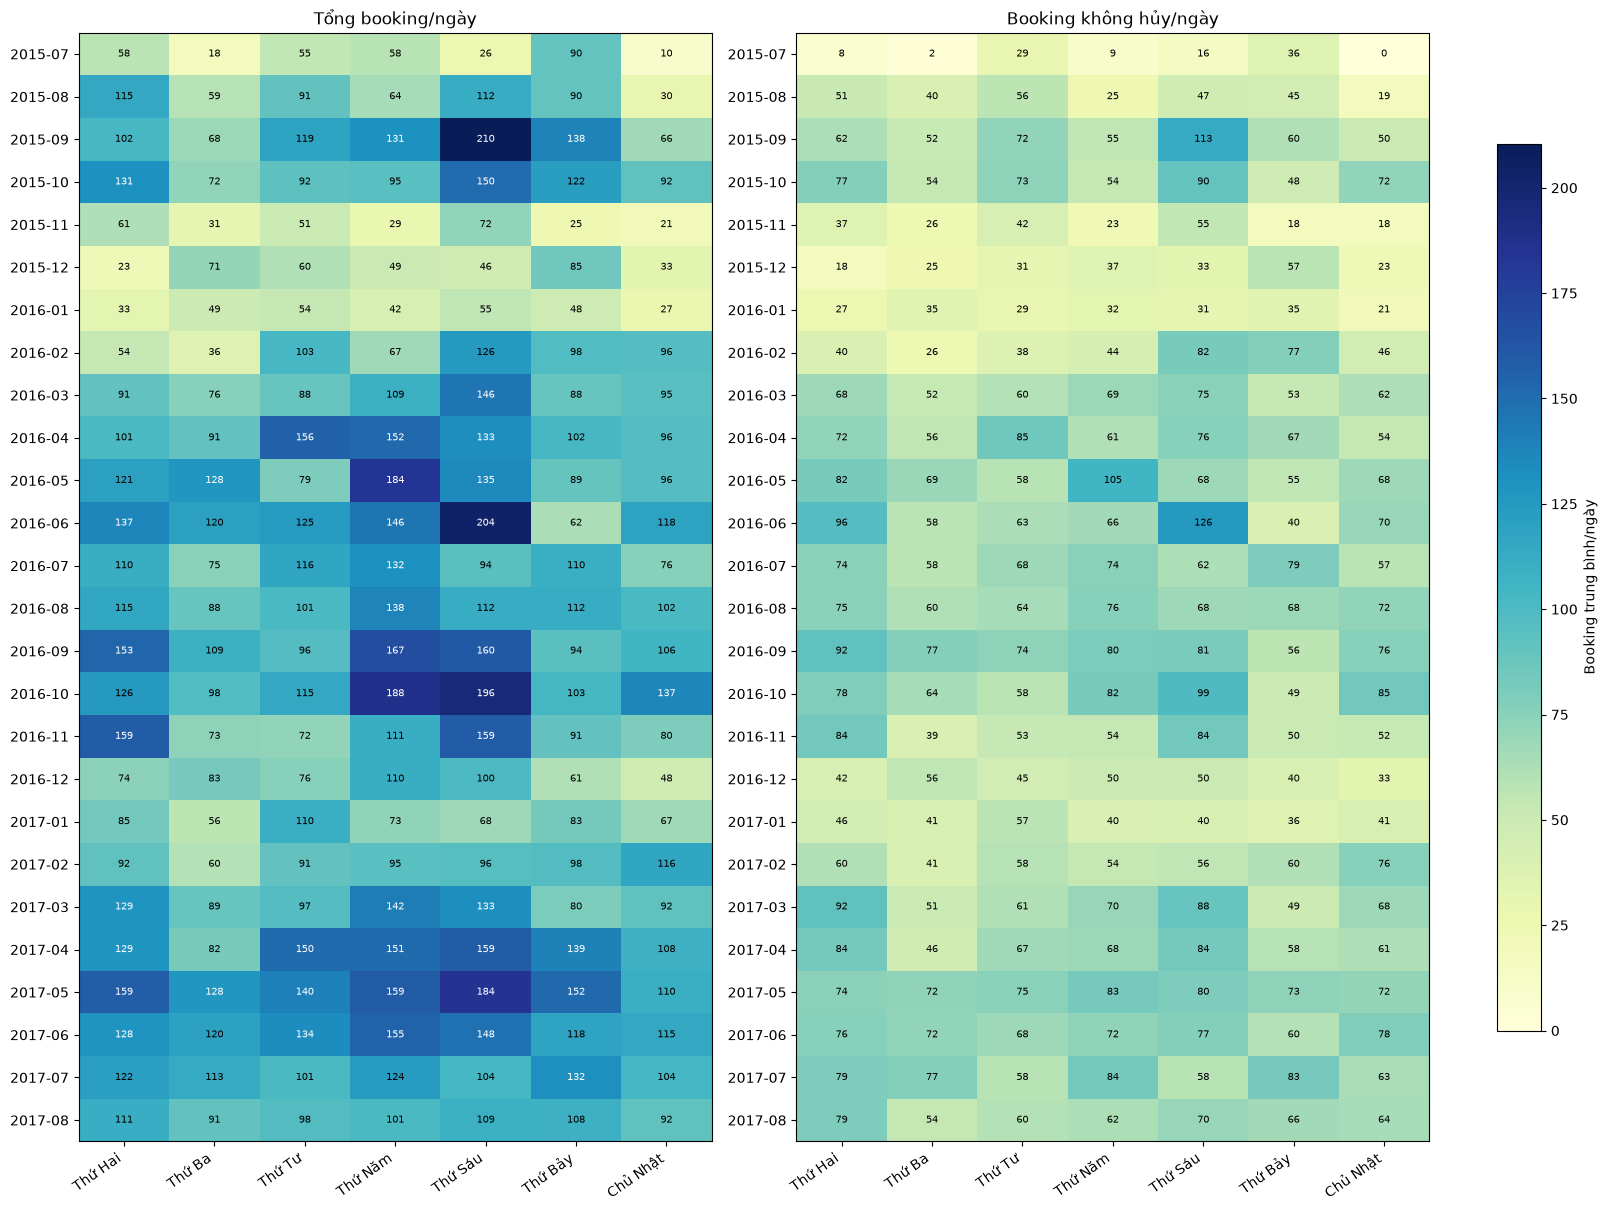

In [39]:
heatmap_total = eda.pivot_table(
    index="month_start",
    columns="weekday_name",
    values="total_bookings",
    aggfunc="mean",
    observed=True,
).reindex(columns=DAY_NAMES)

heatmap_non_canceled = eda.pivot_table(
    index="month_start",
    columns="weekday_name",
    values="non_canceled_bookings",
    aggfunc="mean",
    observed=True,
).reindex(
    index=heatmap_total.index,
    columns=DAY_NAMES,
)

matrices = [
    (heatmap_total, "Tổng booking/ngày"),
    (heatmap_non_canceled, "Booking không hủy/ngày"),
]

color_max = max(
    matrix.max().max()
    for matrix, _ in matrices
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 12),
    constrained_layout=True,
)

for ax, (matrix, title) in zip(axes, matrices):
    values = matrix.to_numpy(
        dtype=float,
        na_value=float("nan"),
    )

    image = ax.imshow(
        values,
        cmap="YlGnBu",
        aspect="auto",
        vmin=0,
        vmax=color_max,
    )

    ax.set_title(title)
    ax.set_xticks(range(len(DAY_NAMES)))
    ax.set_xticklabels(DAY_NAMES, rotation=35, ha="right")

    ax.set_yticks(range(len(matrix.index)))
    ax.set_yticklabels(matrix.index.strftime("%Y-%m"))

    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            value = values[row, column]

            if pd.notna(value):
                ax.text(
                    column,
                    row,
                    f"{value:.0f}",
                    ha="center",
                    va="center",
                    fontsize=7,
                    color=(
                        "white"
                        if value > color_max * 0.6
                        else "black"
                    ),
                )

fig.colorbar(
    image,
    ax=axes,
    label="Booking trung bình/ngày",
    shrink=0.8,
)

plt.show()

### Số đêm ở theo thứ của ngày đến

In [40]:
stay_by_weekday = by_weekday[
    [
        "non_canceled_bookings",
        "stay_valid_booking_count",
        "observed_total_stay_nights",
        "avg_stay_nights",
        "stay_nights_per_day",
    ]
].copy()

display(stay_by_weekday.round(2))

,non_canceled_bookings,stay_valid_booking_count,observed_total_stay_nights,avg_stay_nights,stay_nights_per_day
weekday_name,,,,,
Thứ Hai,7255,7255,22519,3.1,199.28
Thứ Ba,5670,5670,16204,2.86,143.4
Thứ Tư,6572,6572,18204,2.77,159.68
Thứ Năm,6699,6699,18955,2.83,166.27
Thứ Sáu,7801,7801,20612,2.64,182.41
Thứ Bảy,6195,6195,18523,2.99,163.92
Chủ Nhật,6036,6036,20136,3.34,178.19


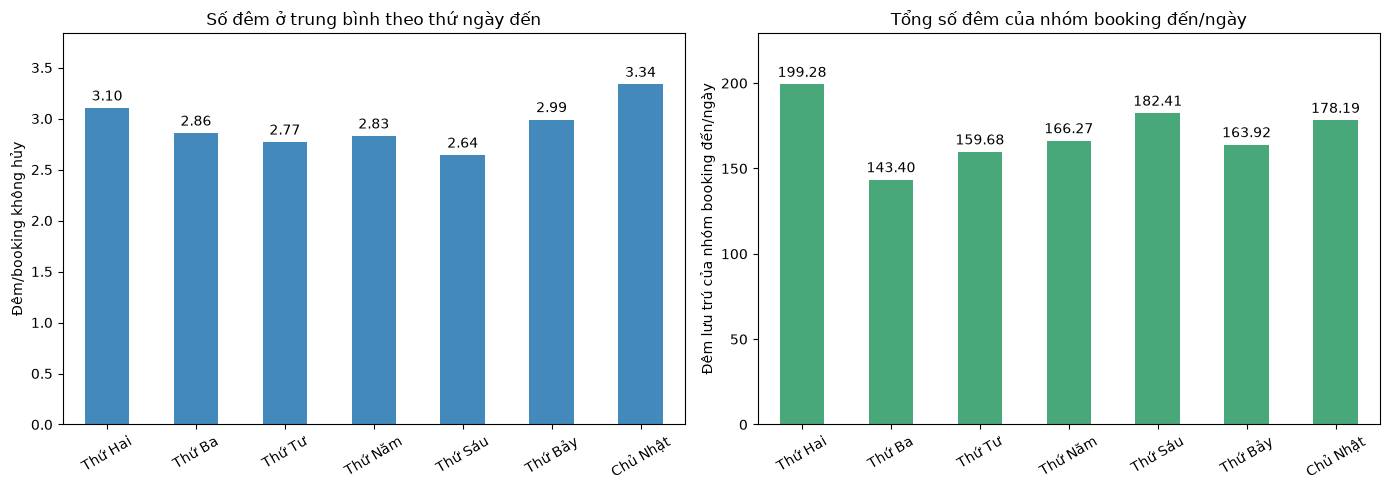

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

stay_by_weekday["avg_stay_nights"].plot.bar(
    ax=axes[0],
    color="#4389bc",
    rot=30,
)

axes[0].set_title("Số đêm ở trung bình theo thứ ngày đến")
axes[0].set_xlabel("")
axes[0].set_ylabel("Đêm/booking không hủy")

stay_by_weekday["stay_nights_per_day"].plot.bar(
    ax=axes[1],
    color="#48a879",
    rot=30,
)

axes[1].set_title("Tổng số đêm của nhóm booking đến/ngày")
axes[1].set_xlabel("")
axes[1].set_ylabel("Đêm lưu trú của nhóm booking đến/ngày")

for ax in axes:
    ax.bar_label(
        ax.containers[0],
        fmt="%.2f",
        padding=3,
    )
    ax.margins(y=0.15)

plt.tight_layout()
plt.show()